# LIBRARIES

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

from imblearn.over_sampling import SMOTE

# EDA

In [58]:
filepath = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(filepath)

In [59]:
print(df.shape)

df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [61]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [62]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [63]:
df.duplicated().sum()

np.int64(0)

In [64]:
cat_cols_before_split = df.select_dtypes(exclude="number")

for col in cat_cols_before_split:
  print(f"{col} ---> {df[col].unique()}")
  print(" ")

customerID ---> <StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str
 
gender ---> <StringArray>
['Female', 'Male']
Length: 2, dtype: str
 
Partner ---> <StringArray>
['Yes', 'No']
Length: 2, dtype: str
 
Dependents ---> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
 
PhoneService ---> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
 
MultipleLines ---> <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
 
InternetService ---> <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
 
OnlineSecurity ---> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
 
OnlineBackup ---> <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
 
DeviceProtectio

In [65]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

# DATA VISUALIZATION


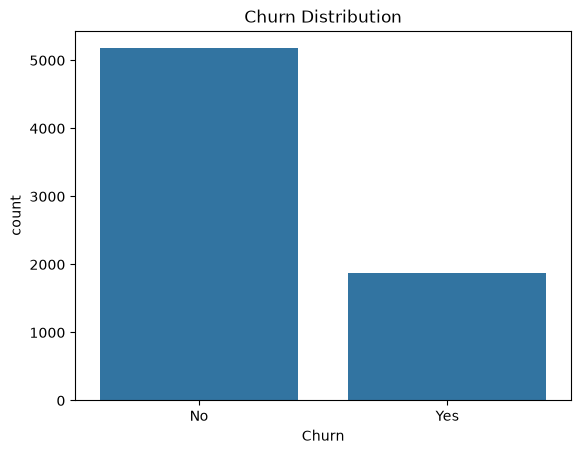

In [66]:
sns.countplot(data=df, x="Churn")
plt.title("Churn Distribution")
plt.show()

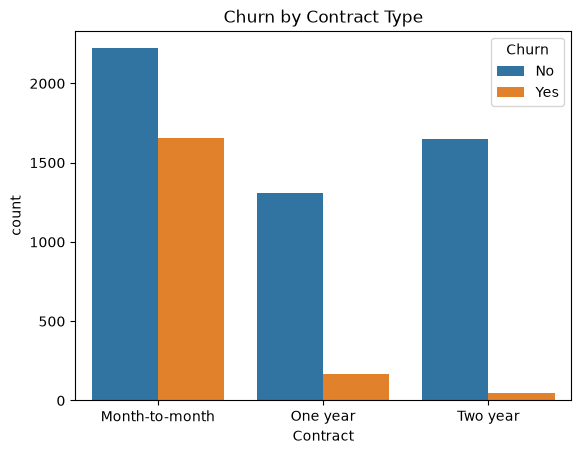

In [67]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.show()

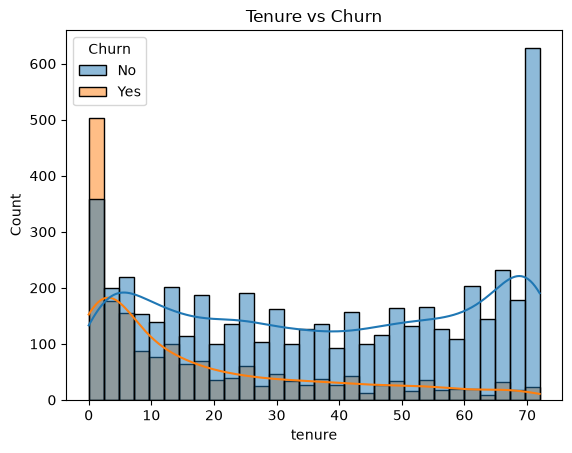

In [68]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True)
plt.title("Tenure vs Churn")
plt.show()

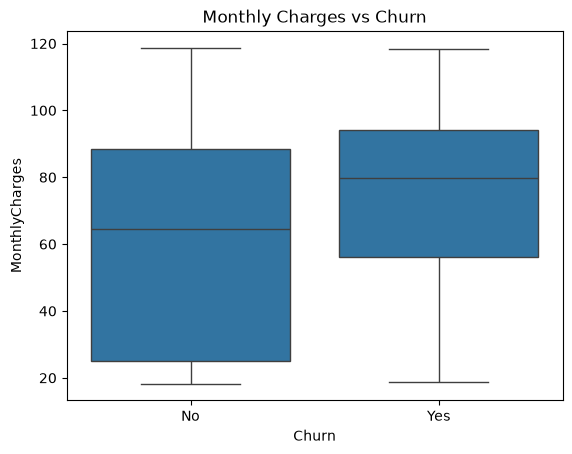

In [69]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.show()

# DATA CLEANING

In [70]:
# converting total charges into number
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isna().sum())

11


In [71]:
df = df.dropna(subset=["TotalCharges"]) # dropping nan in "TotalCharges"

In [72]:
# dropping id column
df = df.drop(columns = "customerID")

df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})   # it's a category, not a number

# SPLITTING DATA

In [73]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42, stratify=y)

In [74]:
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

# SCALING

In [75]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train[num_cols])
X_test_scaled = scaler.transform(X_test[num_cols])

X_train_scaled = pd.DataFrame(X_train_scaled, columns=num_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=num_cols, index=X_test.index)

# ENCODING

In [76]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_train_cat = pd.DataFrame(
    encoder.fit_transform(X_train[cat_cols]),
    columns=encoder.get_feature_names_out(cat_cols), index=X_train.index
)

X_test_cat = pd.DataFrame(
    encoder.transform(X_test[cat_cols]),
    columns=encoder.get_feature_names_out(cat_cols), index=X_test.index
)

In [77]:
X_train_final = pd.concat([X_train_scaled, X_train_cat], axis=1)
X_test_final = pd.concat([X_test_scaled, X_test_cat], axis=1)

print(X_train_final.shape, X_test_final.shape)
X_train_final.head()

(5625, 46) (1407, 46)


,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,SeniorCitizen_No,SeniorCitizen_Yes,Partner_No,Partner_Yes,Dependents_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
1413,1.321816,0.981556,1.659900,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
7003,-0.267410,-0.971546,-0.562252,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3355,1.444064,0.837066,1.756104,1.0,0.0,1.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
4494,-1.204646,0.641092,-0.908326,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3541,0.669826,-0.808787,-0.101561,1.0,0.0,1.0,0.0,0.0,1.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


# CLASS IMBALANCE CORRECTION

In [78]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_final, y_train)

print(y_train_smote.value_counts())

Churn
0    4130
1    4130
Name: count, dtype: int64


# FEATURE SELECTION

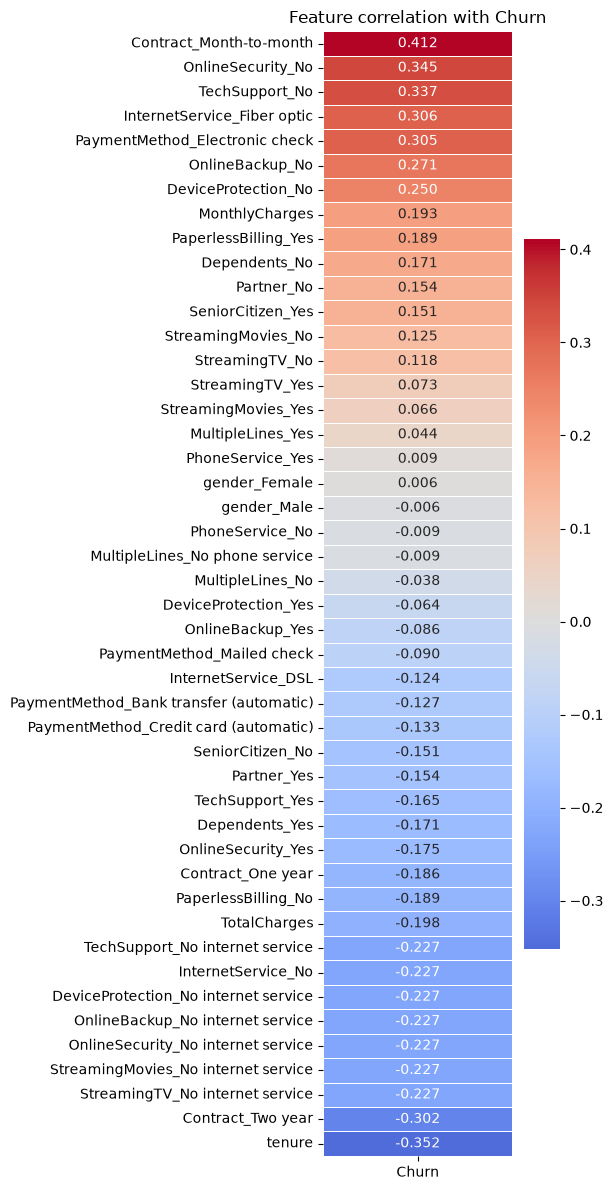

In [79]:
corr = X_train_final.corrwith(y_train).sort_values(ascending=False).to_frame("Churn")

plt.figure(figsize=(6, 12))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5,
    center=0
)
plt.title("Feature correlation with Churn")
plt.tight_layout()
plt.show()

In [80]:
# keeping every feature whose correlation with Churn is above 0.10, to check with multiple max_depths
features_selected = corr[corr["Churn"].abs() > 0.10].index.tolist()
print(len(features_selected), features_selected)

X_train_select = X_train_smote[features_selected]
X_test_select = X_test_final[features_selected]

34 ['Contract_Month-to-month', 'OnlineSecurity_No', 'TechSupport_No', 'InternetService_Fiber optic', 'PaymentMethod_Electronic check', 'OnlineBackup_No', 'DeviceProtection_No', 'MonthlyCharges', 'PaperlessBilling_Yes', 'Dependents_No', 'Partner_No', 'SeniorCitizen_Yes', 'StreamingMovies_No', 'StreamingTV_No', 'InternetService_DSL', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'SeniorCitizen_No', 'Partner_Yes', 'TechSupport_Yes', 'Dependents_Yes', 'OnlineSecurity_Yes', 'Contract_One year', 'PaperlessBilling_No', 'TotalCharges', 'TechSupport_No internet service', 'InternetService_No', 'DeviceProtection_No internet service', 'OnlineBackup_No internet service', 'OnlineSecurity_No internet service', 'StreamingMovies_No internet service', 'StreamingTV_No internet service', 'Contract_Two year', 'tenure']


# MODEL EVALUATION

## LOGISTIC REGRESSION

In [81]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression()

# Fit and evaluate
log_reg.fit(X_train_select, y_train_smote)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [82]:
log_train_pred = log_reg.predict(X_train_select)

log_test_pred = log_reg.predict(X_test_select)

In [83]:
from sklearn.metrics import accuracy_score

# calculate accuracy on the training set
log_train_acc = accuracy_score(y_train_smote, log_train_pred)

# calculate accuracy on the test set
log_test_acc = accuracy_score(y_test, log_test_pred)

print(f"Logistic Regression Train Accuracy: {log_train_acc:.4f}")
print(f"Logistic Regression Test Accuracy: {log_test_acc:.4f}")

Logistic Regression Train Accuracy: 0.7843
Logistic Regression Test Accuracy: 0.7392


### Confusion Matrix

In [84]:
from sklearn.metrics import confusion_matrix

# calculate the confusion matrix for the Logistic Regression model on the test set
log_cm = confusion_matrix(y_test, log_test_pred)

print("Confusion Matrix")
print(log_cm)

Confusion Matrix
[[742 291]
 [ 76 298]]


### Confusion Matrix Heatmap

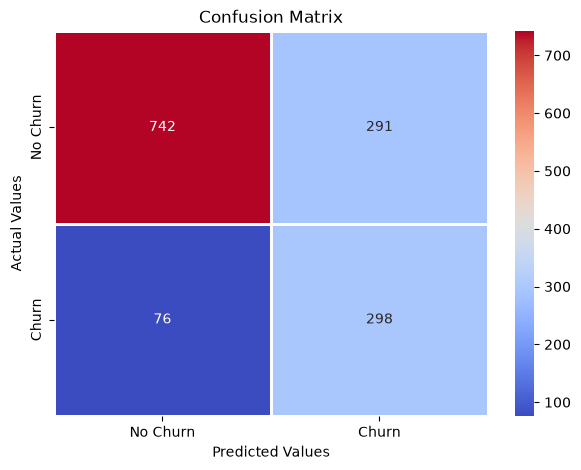

In [85]:
plt.figure(figsize=(7,5))

sns.heatmap(
    log_cm,
    annot=True,
    fmt="d",
    cmap="coolwarm",
    linewidths=1,
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

### Classification Report

In [86]:
from sklearn.metrics import classification_report

# compares true labels (y_test) with predicted labels (log_test_pred)
log_cr = classification_report(y_test, log_test_pred)

print("Classification Report")
print(log_cr)

Classification Report
              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1033
           1       0.51      0.80      0.62       374

    accuracy                           0.74      1407
   macro avg       0.71      0.76      0.71      1407
weighted avg       0.80      0.74      0.75      1407



### Interpretation
- Test accuracy is 0.739 and train accuracy is 0.784. The gap is small, so there is no serious overfitting.
- The model finds 298 of the 374 customers who actually churned (recall 0.80) and misses 76 of them (false negatives).
- It wrongly flags 291 loyal customers as churners (false positives), so churn precision is 0.51 and churn F1 is 0.62.
- A false negative means a lost customer, while a false positive only costs an unnecessary retention offer, so the high recall is a useful property here.

## KNN Classifier
KNN works on distances, so it needs scaled features. The numeric columns were already scaled earlier, and the one-hot columns are 0/1. SMOTE is applied to training data only, never to validation or test data.

In [87]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

### Validation set for choosing k

In [88]:
# split the original (not SMOTE) training data into a smaller train set and a validation set
X_sub, X_val, y_sub, y_val = train_test_split(X_train_final, y_train,
                                              test_size=0.2, random_state=42, stratify=y_train)

# SMOTE only on the smaller train part
smote_val = SMOTE(random_state=42)
X_sub_smote, y_sub_smote = smote_val.fit_resample(X_sub[features_selected], y_sub)

# validation set uses the same selected features
X_val_select = X_val[features_selected]

print(y_sub_smote.value_counts())
print(y_val.value_counts())

Churn
0    3304
1    3304
Name: count, dtype: int64
Churn
0    826
1    299
Name: count, dtype: int64


### Choosing k
I tried odd values of k from 1 to 31 (odd values avoid ties) and compared them using validation F1-score. F1 is used instead of accuracy because the classes are imbalanced and both precision and recall are considered.

Best k: 27
Best validation F1: 0.599


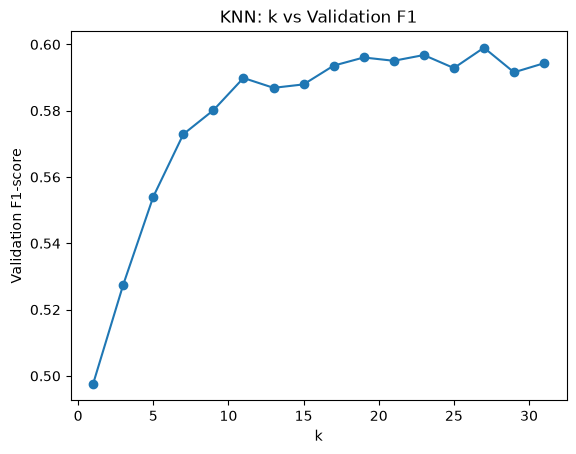

In [89]:
k_values = list(range(1, 32, 2))
val_f1_scores = []

for k in k_values:
    knn_try = KNeighborsClassifier(n_neighbors=k)
    knn_try.fit(X_sub_smote, y_sub_smote)
    val_pred = knn_try.predict(X_val_select)
    val_f1_scores.append(f1_score(y_val, val_pred))

best_k = k_values[np.argmax(val_f1_scores)]
print("Best k:", best_k)
print("Best validation F1:", round(max(val_f1_scores), 4))

plt.plot(k_values, val_f1_scores, marker="o")
plt.xlabel("k")
plt.ylabel("Validation F1-score")
plt.title("KNN: k vs Validation F1")
plt.show()

In [90]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_select, y_train_smote)

# n_neighbors chosen using validation F1-score

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",27
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [91]:
knn_train_pred = knn.predict(X_train_select)

knn_test_pred = knn.predict(X_test_select)

### Accuracy

In [92]:
# calculate accuracy on the training set
knn_train_acc = accuracy_score(y_train_smote, knn_train_pred)

# calculate accuracy on the test set
knn_test_acc = accuracy_score(y_test, knn_test_pred)

print(f"KNN Train Accuracy: {knn_train_acc:.4f}")
print(f"KNN Test Accuracy: {knn_test_acc:.4f}")

KNN Train Accuracy: 0.7965
KNN Test Accuracy: 0.7043


### Confusion Matrix

Confusion Matrix
[[679 354]
 [ 62 312]]


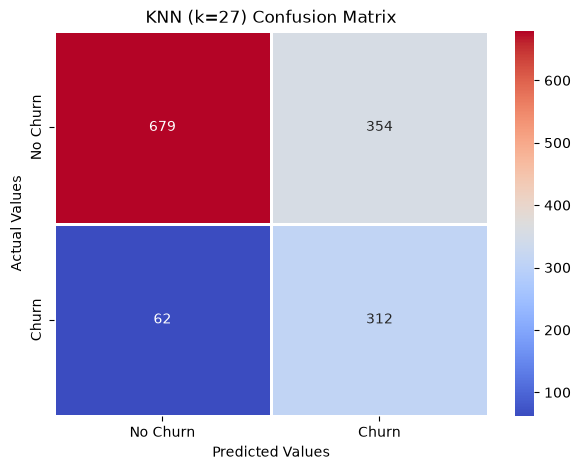

In [93]:
# calculate the confusion matrix for the KNN model on the test set
knn_cm = confusion_matrix(y_test, knn_test_pred)

print("Confusion Matrix")
print(knn_cm)

plt.figure(figsize=(7,5))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="coolwarm",
    linewidths=1,
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title(f"KNN (k={best_k}) Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

### Classification Report

In [94]:
print("Precision:", round(precision_score(y_test, knn_test_pred), 4))
print("Recall   :", round(recall_score(y_test, knn_test_pred), 4))
print("F1-score :", round(f1_score(y_test, knn_test_pred), 4))

# compares true labels (y_test) with predicted labels (knn_test_pred)
knn_cr = classification_report(y_test, knn_test_pred)

print("Classification Report")
print(knn_cr)

Precision: 0.4685
Recall   : 0.8342
F1-score : 0.6
Classification Report
              precision    recall  f1-score   support

           0       0.92      0.66      0.77      1033
           1       0.47      0.83      0.60       374

    accuracy                           0.70      1407
   macro avg       0.69      0.75      0.68      1407
weighted avg       0.80      0.70      0.72      1407



### Thresholds on validation set

In [95]:
# model trained on the smaller train part, so validation stays unseen
knn_val_model = KNeighborsClassifier(n_neighbors=best_k)
knn_val_model.fit(X_sub_smote, y_sub_smote)
knn_val_proba = knn_val_model.predict_proba(X_val_select)[:, 1]

thresholds = [0.3, 0.5, 0.7]
knn_threshold_results = []

for t in thresholds:
    val_pred_t = (knn_val_proba >= t).astype(int)
    knn_threshold_results.append({
        "Threshold": t,
        "Accuracy": accuracy_score(y_val, val_pred_t),
        "Precision": precision_score(y_val, val_pred_t, zero_division=0),
        "Recall": recall_score(y_val, val_pred_t),
        "F1": f1_score(y_val, val_pred_t)
    })

pd.DataFrame(knn_threshold_results)

,Threshold,Accuracy,Precision,Recall,F1
0,0.3,0.616000,0.402349,0.916388,0.559184
1,0.5,0.712000,0.475442,0.809365,0.599010
2,0.7,0.770667,0.558739,0.652174,0.601852


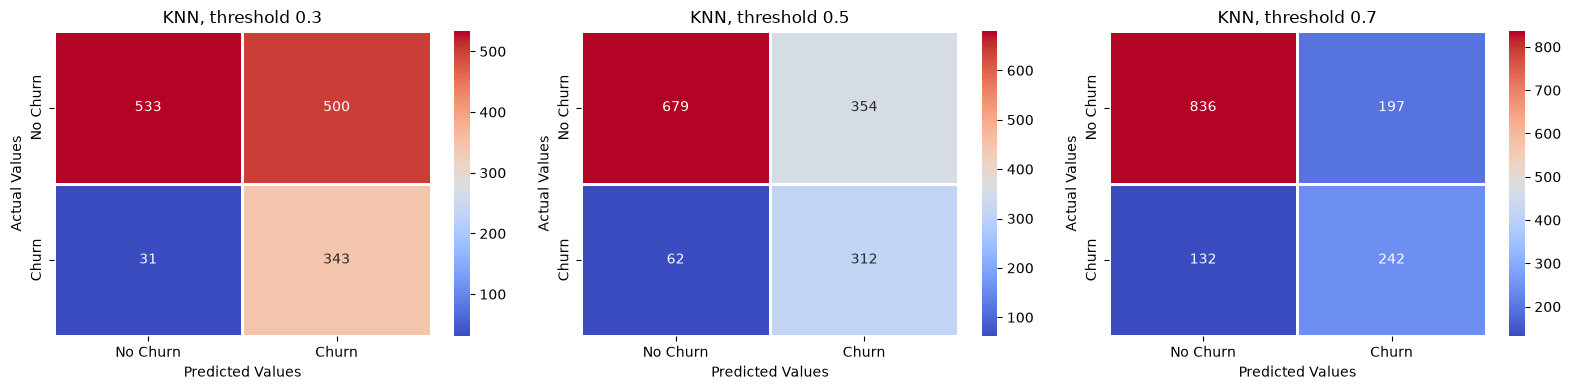

Threshold 0.3: Precision=0.407, Recall=0.917, F1=0.564, False Positives=500, False Negatives=31
Threshold 0.5: Precision=0.468, Recall=0.834, F1=0.600, False Positives=354, False Negatives=62
Threshold 0.7: Precision=0.551, Recall=0.647, F1=0.595, False Positives=197, False Negatives=132


In [96]:
knn_test_proba = knn.predict_proba(X_test_select)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, t in enumerate(thresholds):
    pred_t = (knn_test_proba >= t).astype(int)
    cm_t = confusion_matrix(y_test, pred_t)

    sns.heatmap(cm_t, annot=True, fmt="d", cmap="coolwarm", linewidths=1, ax=axes[i],
                xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
    axes[i].set_title(f"KNN, threshold {t}")
    axes[i].set_xlabel("Predicted Values")
    axes[i].set_ylabel("Actual Values")

plt.tight_layout()
plt.show()

for t in thresholds:
    pred_t = (knn_test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_t).ravel()
    print(f"Threshold {t}: Precision={precision_score(y_test, pred_t, zero_division=0):.3f}, "
          f"Recall={recall_score(y_test, pred_t):.3f}, F1={f1_score(y_test, pred_t):.3f}, "
          f"False Positives={fp}, False Negatives={fn}")

### Interpretation
- k = 27 was chosen using validation F1 (0.599). Test accuracy is 0.704 and train accuracy is 0.797.
- KNN finds 312 of the 374 churners (recall 0.83), the best recall of all models, and misses only 62 (false negatives). The cost is 354 false positives, so churn precision is only 0.47 (F1 0.60).
- Thresholds: lowering the threshold to 0.3 raises recall to 0.92 (only 31 churners missed) but flags 500 loyal customers wrongly. Raising it to 0.7 gives fewer false alarms (197) but misses 132 churners (recall 0.65). On validation F1, 0.5 and 0.7 are almost the same (0.599 vs 0.602) and 0.3 is lower (0.559).
- I keep 0.5 as the balanced choice. If losing a customer is much costlier than a wasted offer, 0.3 would be preferable.

## Decision Tree Classifier

In [97]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

depths = [3, 5, 10, None]
dt_results = []

for d in depths:
    tree_val = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree_val.fit(X_sub_smote, y_sub_smote)
    val_f1 = f1_score(y_val, tree_val.predict(X_val_select))

    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree.fit(X_train_select, y_train_smote)
    train_pred = tree.predict(X_train_select)
    test_pred = tree.predict(X_test_select)

    dt_results.append({
        "depth": d,
        "max_depth": str(d),
        "Train Acc": accuracy_score(y_train_smote, train_pred),
        "Test Acc": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred),
        "Recall": recall_score(y_test, test_pred),
        "F1": f1_score(y_test, test_pred),
        "Val F1": val_f1
    })

dt_results_df = pd.DataFrame(dt_results).drop(columns="depth").round(4)
dt_results_df

,max_depth,Train Acc,Test Acc,Precision,Recall,F1,Val F1
0,3,0.7734,0.7207,0.4835,0.7460,0.5868,0.5782
1,5,0.8007,0.7399,0.5072,0.7487,0.6048,0.6056
2,10,0.8707,0.7200,0.4811,0.6818,0.5642,0.5789
3,None,0.9987,0.7050,0.4549,0.5535,0.4994,0.5163


### Final depth
I chose the max_depth with the highest validation F1, and refit the tree with it on the full training data.

In [98]:
best_depth = max(dt_results, key=lambda r: r["Val F1"])["depth"]
print("Chosen max_depth:", best_depth)

dt = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt.fit(X_train_select, y_train_smote)

Chosen max_depth: 5


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [99]:
dt_train_pred = dt.predict(X_train_select)

dt_test_pred = dt.predict(X_test_select)

### Accuracy

In [100]:
# calculate accuracy on the training set
dt_train_acc = accuracy_score(y_train_smote, dt_train_pred)

# calculate accuracy on the test set
dt_test_acc = accuracy_score(y_test, dt_test_pred)

print(f"Decision Tree Train Accuracy: {dt_train_acc:.4f}")
print(f"Decision Tree Test Accuracy: {dt_test_acc:.4f}")

Decision Tree Train Accuracy: 0.8007
Decision Tree Test Accuracy: 0.7399


### Confusion matrix

In [101]:
# calculate the confusion matrix for the Decision Tree model on the test set
dt_cm = confusion_matrix(y_test, dt_test_pred)

print("Confusion Matrix")
print(dt_cm)

Confusion Matrix
[[761 272]
 [ 94 280]]


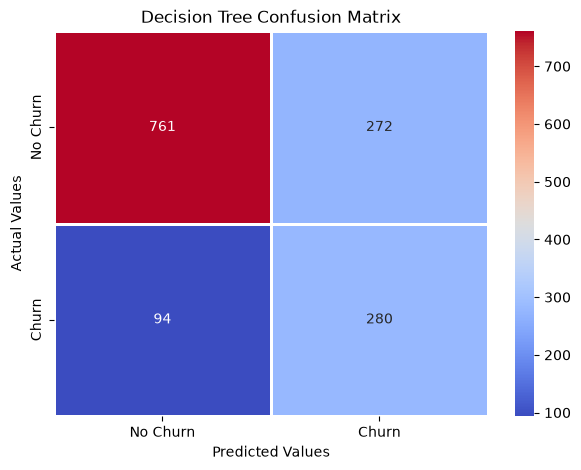

In [102]:
plt.figure(figsize=(7,5))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="coolwarm",
    linewidths=1,
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

### Classification Report

In [103]:
# compares true labels (y_test) with predicted labels (dt_test_pred)
dt_cr = classification_report(y_test, dt_test_pred)

print("Classification Report")
print(dt_cr)

Classification Report
              precision    recall  f1-score   support

           0       0.89      0.74      0.81      1033
           1       0.51      0.75      0.60       374

    accuracy                           0.74      1407
   macro avg       0.70      0.74      0.71      1407
weighted avg       0.79      0.74      0.75      1407



### Visualizing the tree
The final tree (max_depth = 5) is too large to read, so I plot a tree with max_depth = 3. Each box shows the question asked, the number of samples, and the majority class.

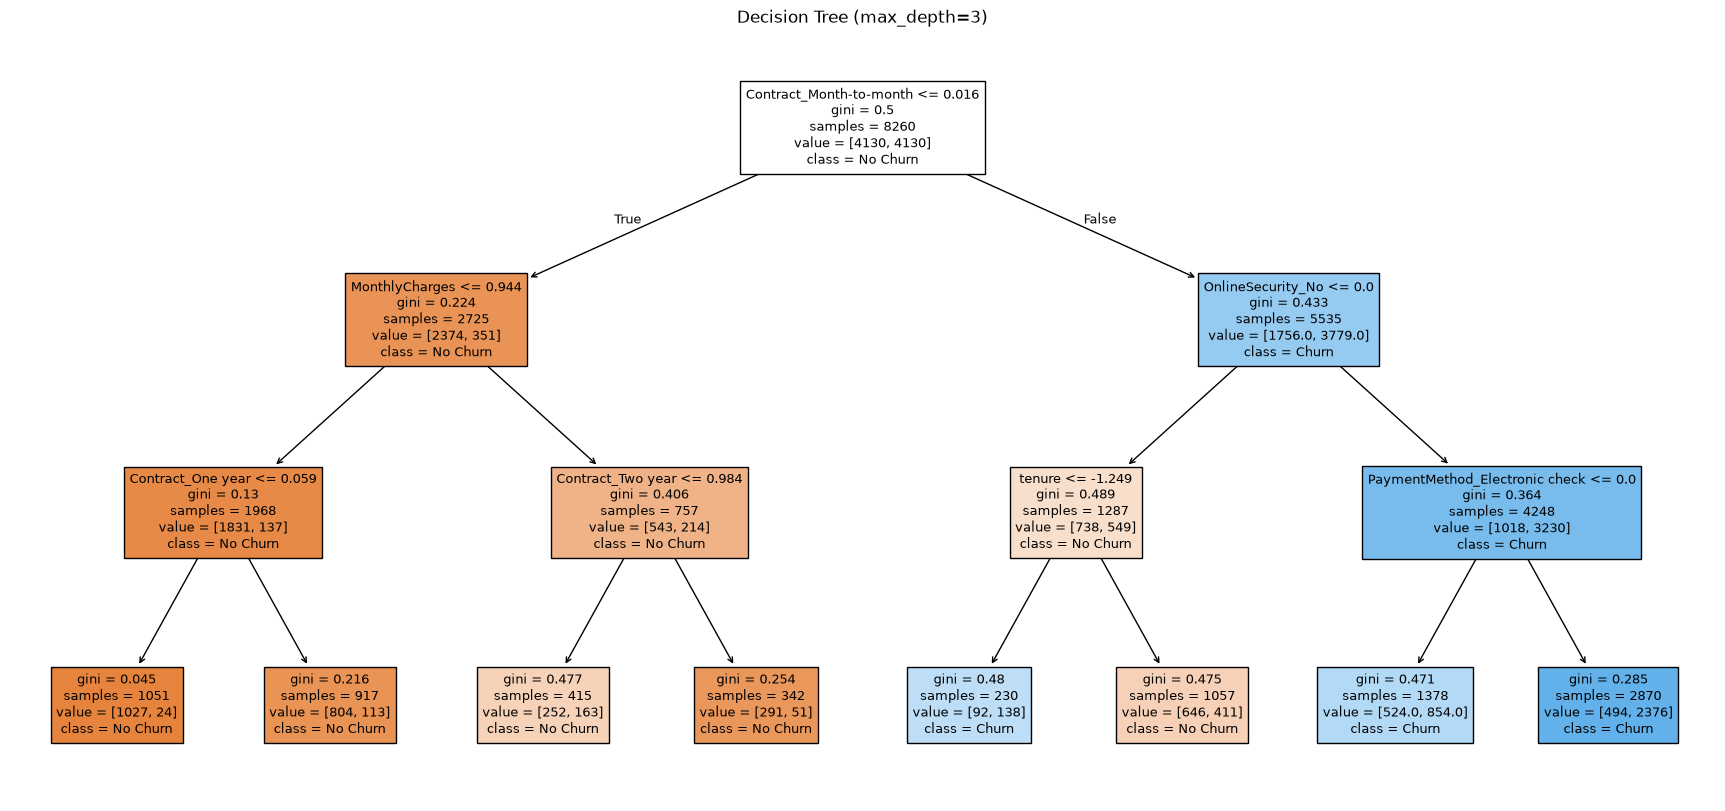

In [104]:
tree_plot = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_plot.fit(X_train_select, y_train_smote)

plt.figure(figsize=(22, 10))
plot_tree(
    tree_plot,
    feature_names=features_selected,
    class_names=["No Churn", "Churn"],
    filled=True,
    fontsize=9
)
plt.title("Decision Tree (max_depth=3)")
plt.show()

### Interpretation
- The final tree uses max_depth = 5, chosen by validation F1 (0.606). Test accuracy is 0.740 and train accuracy is 0.801.
- It finds 280 of the 374 churners (recall 0.75) and misses 94 (false negatives).
- It wrongly flags 272 loyal customers (false positives), so churn precision is 0.51 and churn F1 is 0.60.

### effect of max_depth
- From depth 3 to 5, test F1 improved (0.587 to 0.605) because the tree could capture more patterns.
- At depth 10 and None the train accuracy kept rising (0.871 and 0.999), but test accuracy and F1 fell (F1 0.564 and 0.499; recall dropped to 0.55 for None). The tree memorised the training data, which is overfitting.
- So deeper does not always mean better. The best depth here is 5.

## Final Comparison

| Model | Accuracy | Churn Precision | Churn Recall | Churn F1 | False Positives | False Negatives |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.739 | 0.51 | 0.80 | 0.62 | 291 | 76 |
| KNN (k=27) | 0.704 | 0.47 | 0.83 | 0.60 | 354 | 62 |
| Decision Tree (max_depth=5) | 0.740 | 0.51 | 0.75 | 0.60 | 272 | 94 |

### Discussion
- **Highest accuracy:** the Decision Tree (0.740), but Logistic Regression is practically equal (0.739). Accuracy is not very informative here, since always predicting "No Churn" would score 0.734.
- **Which model finds more leaving customers:** KNN, with recall 0.83 (312 of 374 churners), followed by Logistic Regression (0.80) and the Decision Tree (0.75). KNN pays for this with the most false positives (354).
- **False positive vs false negative:** a false positive is a loyal customer flagged as a churner (wasted offer). A false negative is a churner we miss (lost customer, usually costlier).
- **Effect of max_depth / deeper is not always better:** see the Decision Tree discussion above.

### Recommendation
I recommend **Logistic Regression**. It has the best churn F1 (0.62), a high recall (0.80), and fewer false alarms than KNN. It is also simple and fast. If catching every possible churner mattered most, KNN with a lower threshold would be an alternative, at the cost of many more false positives.